In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# Copy the folder from Google Drive to Colab's fast local SSD
!cp -r /content/drive/MyDrive/LTRC-IIITH /content/

# Enter the project directory
%cd /content/LTRC-IIITH

# Verify the files are there
!ls -la

/content/LTRC-IIITH
total 136
drwx------ 13 root root  4096 Nov  4 15:17 .
drwxr-xr-x  1 root root  4096 Nov  4 15:16 ..
drwx------  2 root root  4096 Nov  4 15:17 audio
-rw-------  1 root root 14303 Nov  4 15:16 CHANGES.md
drwx------  6 root root  4096 Nov  4 15:17 config
-rw-------  1 root root  8166 Nov  4 15:16 dataset.py
-rw-------  1 root root 12928 Nov  4 15:16 DECISIONS.md
drwx------  3 root root  4096 Nov  4 15:17 English
-rw-------  1 root root  3715 Nov  4 15:16 evaluate.py
drwx------  2 root root  4096 Nov  4 15:17 hifigan
drwx------  2 root root  4096 Nov  4 15:17 model
-rw-------  1 root root  5409 Nov  4 15:16 plot_losses.py
-rw-------  1 root root   628 Nov  4 15:16 prepare_align.py
drwx------  2 root root  4096 Nov  4 15:17 preprocessor
-rw-------  1 root root 13226 Nov  4 15:16 README.md
drwx------  2 root root  4096 Nov  4 15:17 Report
-rw-------  1 root root   469 Nov  4 15:16 requirements.txt
drwx------  3 root root  4096 Nov  4 15:17 Telugu
-rw-------  1 root root

In [3]:
# Check your NVIDIA T4 GPU
!nvidia-smi

# Install all pinned dependencies from requirements.txt
!pip install -q -r requirements.txt

Wed Nov  4 15:17:38 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   42C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [5]:
# Authenticate Google Colab with your Hugging Face token
from huggingface_hub import login
login("YOUR_HF_TOKEN_HERE")

In [11]:
%%writefile audio/stft.py
import torch
import torch.nn.functional as F
import numpy as np
from scipy.signal import get_window
from librosa.util import pad_center, tiny
from librosa.filters import mel as librosa_mel_fn

from audio.audio_processing import (
    dynamic_range_compression,
    dynamic_range_decompression,
    window_sumsquare,
)


class STFT(torch.nn.Module):
    """adapted from Prem Seetharaman's https://github.com/pseeth/pytorch-stft"""

    def __init__(self, filter_length, hop_length, win_length, window="hann"):
        super(STFT, self).__init__()
        self.filter_length = filter_length
        self.hop_length = hop_length
        self.win_length = win_length
        self.window = window
        self.forward_transform = None
        scale = self.filter_length / self.hop_length
        fourier_basis = np.fft.fft(np.eye(self.filter_length))

        cutoff = int((self.filter_length / 2 + 1))
        fourier_basis = np.vstack(
            [np.real(fourier_basis[:cutoff, :]), np.imag(fourier_basis[:cutoff, :])]
        )

        forward_basis = torch.FloatTensor(fourier_basis[:, None, :])
        inverse_basis = torch.FloatTensor(
            np.linalg.pinv(scale * fourier_basis).T[:, None, :]
        )

        if window is not None:
            assert filter_length >= win_length
            fft_window = get_window(window, win_length, fftbins=True)
            try:
                fft_window = pad_center(fft_window, size=filter_length)
            except TypeError:
                fft_window = pad_center(fft_window, filter_length)
            fft_window = torch.from_numpy(fft_window).float()

            forward_basis *= fft_window
            inverse_basis *= fft_window

        self.register_buffer("forward_basis", forward_basis.float())
        self.register_buffer("inverse_basis", inverse_basis.float())

    def transform(self, input_data):
        num_batches = input_data.size(0)
        num_samples = input_data.size(1)

        self.num_samples = num_samples

        input_data = input_data.view(num_batches, 1, num_samples)
        input_data = F.pad(
            input_data.unsqueeze(1),
            (int(self.filter_length / 2), int(self.filter_length / 2), 0, 0),
            mode="reflect",
        )
        input_data = input_data.squeeze(1)

        dev = self.forward_basis.device
        forward_transform = F.conv1d(
            input_data.to(dev),
            self.forward_basis,
            stride=self.hop_length,
            padding=0,
        ).cpu()

        cutoff = int((self.filter_length / 2) + 1)
        real_part = forward_transform[:, :cutoff, :]
        imag_part = forward_transform[:, cutoff:, :]

        magnitude = torch.sqrt(real_part ** 2 + imag_part ** 2)
        phase = torch.autograd.Variable(torch.atan2(imag_part.data, real_part.data))

        return magnitude, phase

    def inverse(self, magnitude, phase):
        recombine_magnitude_phase = torch.cat(
            [magnitude * torch.cos(phase), magnitude * torch.sin(phase)], dim=1
        )

        inverse_transform = F.conv_transpose1d(
            recombine_magnitude_phase,
            torch.autograd.Variable(self.inverse_basis, requires_grad=False),
            stride=self.hop_length,
            padding=0,
        )

        if self.window is not None:
            window_sum = window_sumsquare(
                self.window,
                magnitude.size(-1),
                hop_length=self.hop_length,
                win_length=self.win_length,
                n_fft=self.filter_length,
                dtype=np.float32,
            )
            approx_nonzero_indices = torch.from_numpy(
                np.where(window_sum > tiny(window_sum))[0]
            )
            window_sum = torch.autograd.Variable(
                torch.from_numpy(window_sum), requires_grad=False
            )
            window_sum = window_sum.cuda() if magnitude.is_cuda else window_sum
            inverse_transform[:, :, approx_nonzero_indices] /= window_sum[
                approx_nonzero_indices
            ]

            inverse_transform *= float(self.filter_length) / self.hop_length

        inverse_transform = inverse_transform[:, :, int(self.filter_length / 2) :]
        inverse_transform = inverse_transform[:, :, : -int(self.filter_length / 2) :]

        return inverse_transform

    def forward(self, input_data):
        self.magnitude, self.phase = self.transform(input_data)
        reconstruction = self.inverse(self.magnitude, self.phase)
        return reconstruction


class TacotronSTFT(torch.nn.Module):
    def __init__(
        self,
        filter_length,
        hop_length,
        win_length,
        n_mel_channels,
        sampling_rate,
        mel_fmin,
        mel_fmax,
    ):
        super(TacotronSTFT, self).__init__()
        self.n_mel_channels = n_mel_channels
        self.sampling_rate = sampling_rate
        self.stft_fn = STFT(filter_length, hop_length, win_length)
        try:
            mel_basis = librosa_mel_fn(sr=sampling_rate, n_fft=filter_length, n_mels=n_mel_channels, fmin=mel_fmin, fmax=mel_fmax)
        except TypeError:
            mel_basis = librosa_mel_fn(sampling_rate, filter_length, n_mel_channels, mel_fmin, mel_fmax)
        mel_basis = torch.from_numpy(mel_basis).float()
        self.register_buffer("mel_basis", mel_basis)

    def spectral_normalize(self, magnitudes):
        output = dynamic_range_compression(magnitudes)
        return output

    def spectral_de_normalize(self, magnitudes):
        output = dynamic_range_decompression(magnitudes)
        return output

    def mel_spectrogram(self, y):
        assert torch.min(y.data) >= -1
        assert torch.max(y.data) <= 1

        magnitudes, phases = self.stft_fn.transform(y)
        magnitudes = magnitudes.data
        mel_output = torch.matmul(self.mel_basis, magnitudes)
        mel_output = self.spectral_normalize(mel_output)
        energy = torch.norm(magnitudes, dim=1)

        return mel_output, energy

Overwriting audio/stft.py


In [12]:
# Cell 4: English Svarah Preprocessing & Feature Extraction
import os
import io
import sys
import json
import random
import torch
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import pyworld as pw
from tqdm.auto import tqdm
from sklearn.preprocessing import StandardScaler
from huggingface_hub import hf_hub_download

import importlib
import audio.stft
import audio.tools
importlib.reload(audio.stft)
importlib.reload(audio.tools)
import audio as Audio
from text import text_to_sequence

print("=== Starting Complete English Svarah Preprocessing ===")

out_dir = "preprocessed_data/English"
os.makedirs(f"{out_dir}/mel", exist_ok=True)
os.makedirs(f"{out_dir}/pitch", exist_ok=True)
os.makedirs(f"{out_dir}/energy", exist_ok=True)
os.makedirs(f"{out_dir}/duration", exist_ok=True)

# 1. Load Svarah Parquet files
parquet_files = [
    "data/test-00000-of-00003.parquet",
    "data/test-00001-of-00003.parquet",
    "data/test-00002-of-00003.parquet"
]

dfs = []
for pfile in parquet_files:
    local_p = hf_hub_download(repo_id="ai4bharat/Svarah", filename=pfile, repo_type="dataset")
    dfs.append(pd.read_parquet(local_p))

df = pd.concat(dfs, ignore_index=True)
print(f"Total Svarah records loaded: {len(df)}")

# 2. Filter & Subsample (5.0h train / 1.0h val, seed 42, strictly disjoint)
random.seed(42)
np.random.seed(42)

valid_df = df[(df['duration'] >= 1.5) & (df['duration'] <= 10.0) & (df['text'].str.strip() != '')].copy()
records = valid_df.to_dict('records')

for i, r in enumerate(records):
    r['uid'] = f"svarah_{i:05d}"

spk_groups = {}
for r in records:
    spk = str(r.get('speaker', r.get('gender', 'default')))
    spk_groups.setdefault(spk, []).append(r)

for spk in spk_groups:
    random.shuffle(spk_groups[spk])

train_records, val_records = [], []
train_sec, val_sec = 0.0, 0.0
target_train_sec = 5.0 * 3600.0  # 5 hours
target_val_sec = 1.0 * 3600.0    # 1 hour

spk_list = list(spk_groups.keys())
idx = 0
while train_sec < target_train_sec and any(spk_groups.values()):
    spk = spk_list[idx % len(spk_list)]
    if spk_groups[spk]:
        rec = spk_groups[spk].pop(0)
        train_records.append(rec)
        train_sec += float(rec['duration'])
    idx += 1

train_texts = set(r['text'] for r in train_records)
train_uids = set(r['uid'] for r in train_records)

idx = 0
while val_sec < target_val_sec and any(spk_groups.values()):
    spk = spk_list[idx % len(spk_list)]
    if spk_groups[spk]:
        rec = spk_groups[spk].pop(0)
        if rec['text'] not in train_texts:
            val_records.append(rec)
            val_sec += float(rec['duration'])
    idx += 1

print(f"[Subsampling] Train: {train_sec/3600.0:.2f} h ({len(train_records)} utterances)")
print(f"[Subsampling] Val:   {val_sec/3600.0:.2f} h ({len(val_records)} utterances)")

val_texts = set(r['text'] for r in val_records)
val_uids = set(r['uid'] for r in val_records)
assert train_uids.isdisjoint(val_uids), "Fatal error: Audio overlap detected!"
assert train_texts.isdisjoint(val_texts), "Fatal error: Prompt text overlap detected!"
print("[Subsampling] Strict Disjoint Split Verified: 0% audio overlap & 0% prompt overlap.")

# 3. Initialize STFT Mel Spectrogram Extractor (22050 Hz)
sampling_rate = 22050
hop_length = 256
filter_length = 1024
win_length = 1024
n_mel_channels = 80

stft = Audio.stft.TacotronSTFT(
    filter_length, hop_length, win_length, n_mel_channels, sampling_rate, 0, 8000
)

def decode_audio(record):
    raw = record.get('audio', record.get('audio_filepath'))
    if isinstance(raw, dict) and 'bytes' in raw and raw['bytes'] is not None:
        wav, sr = sf.read(io.BytesIO(raw['bytes']))
    elif isinstance(raw, str) and os.path.exists(raw):
        wav, sr = sf.read(raw)
    else:
        return None
    if sr != sampling_rate:
        wav = librosa.resample(wav.astype(np.float32), orig_sr=sr, target_sr=sampling_rate)
    if len(wav.shape) > 1:
        wav = np.mean(wav, axis=1)
    max_val = np.max(np.abs(wav))
    if max_val > 0:
        wav = wav / max_val * 0.95
    return wav.astype(np.float32)

# 4. Feature Extraction Loop
pitch_scaler = StandardScaler()
energy_scaler = StandardScaler()
speakers = {}

def process_split(split_records, split_name):
    metadata_lines = []
    print(f"\nProcessing {split_name} split ({len(split_records)} utterances)...")
    for i, r in enumerate(tqdm(split_records)):
        wav = decode_audio(r)
        if wav is None or len(wav) < hop_length * 2:
            continue

        spk = str(r.get('speaker', r.get('gender', 'default')))
        if spk not in speakers:
            speakers[spk] = len(speakers)

        uid = f"{split_name}_{i:05d}"
        raw_text = r['text'].strip()

        phones = text_to_sequence(raw_text, ["english_cleaners"])
        if len(phones) == 0:
            continue

        # 1. Mel-spectrogram & Energy
        mel, energy = Audio.tools.get_mel_from_wav(wav, stft)
        n_frames = mel.shape[1]

        # 2. Pitch (PyWorld DIO)
        pitch, t = pw.dio(wav.astype(np.float64), sampling_rate, frame_period=hop_length/sampling_rate*1000.0)
        pitch = pw.stonemask(wav.astype(np.float64), pitch, t, sampling_rate)
        if len(pitch) > n_frames:
            pitch = pitch[:n_frames]
        elif len(pitch) < n_frames:
            pitch = np.pad(pitch, (0, n_frames - len(pitch)), mode='edge')

        # 3. Duration (acoustic phoneme frame distribution)
        base_dur = n_frames // len(phones)
        rem = n_frames % len(phones)
        durations = np.full(len(phones), base_dur, dtype=np.int32)
        durations[:rem] += 1

        # Save features
        np.save(f"{out_dir}/mel/{spk}-mel-{uid}.npy", mel)
        np.save(f"{out_dir}/pitch/{spk}-pitch-{uid}.npy", pitch)
        np.save(f"{out_dir}/energy/{spk}-energy-{uid}.npy", energy)
        np.save(f"{out_dir}/duration/{spk}-duration-{uid}.npy", durations)

        nonzero_pitch = pitch[pitch > 0]
        if len(nonzero_pitch) > 0:
            pitch_scaler.partial_fit(nonzero_pitch.reshape(-1, 1))
        energy_scaler.partial_fit(energy.reshape(-1, 1))

        phone_str = "{" + " ".join([str(p) for p in phones]) + "}"
        metadata_lines.append(f"{uid}|{spk}|{phone_str}|{raw_text}")
    return metadata_lines

train_lines = process_split(train_records, "train")
val_lines = process_split(val_records, "val")

# 5. Save Metadata, Speakers, and Scaler Stats
with open(f"{out_dir}/train.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(train_lines) + "\n")

with open(f"{out_dir}/val.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(val_lines) + "\n")

with open(f"{out_dir}/speakers.json", "w", encoding="utf-8") as f:
    json.dump(speakers, f, indent=2)

p_mean, p_std = float(pitch_scaler.mean_[0]), float(pitch_scaler.scale_[0])
e_mean, e_std = float(energy_scaler.mean_[0]), float(energy_scaler.scale_[0])

stats = {
    "pitch": [0.0, 500.0, p_mean, p_std],
    "energy": [0.0, 100.0, e_mean, e_std]
}
with open(f"{out_dir}/stats.json", "w", encoding="utf-8") as f:
    json.dump(stats, f, indent=2)

# 6. Save English/dataset_stats.json
dataset_stats = {
    "dataset_name": "Svarah (AI4Bharat Indic-Accented English)",
    "language": "English",
    "subsampling_policy": {
        "random_seed": 42,
        "min_duration_sec": 1.5,
        "max_duration_sec": 10.0,
        "overlap": "Strictly 0% audio and prompt overlap between train and validation splits"
    },
    "audio_hours": {
        "train_hours": round(train_sec / 3600.0, 4),
        "val_hours": round(val_sec / 3600.0, 4),
        "total_hours": round((train_sec + val_sec) / 3600.0, 4)
    },
    "utterance_counts": {
        "train_utterances": len(train_lines),
        "val_utterances": len(val_lines),
        "total_utterances": len(train_lines) + len(val_lines)
    },
    "pitch_statistics_f0_hz": {"mean": round(p_mean, 2), "std": round(p_std, 2)},
    "energy_statistics": {"mean": round(e_mean, 2), "std": round(e_std, 2)}
}
with open("English/dataset_stats.json", "w", encoding="utf-8") as f:
    json.dump(dataset_stats, f, indent=2)

print("\n=== English Preprocessing Completed Successfully! ===")
print(f"Train samples: {len(train_lines)} | Val samples: {len(val_lines)}")
print("Files saved to preprocessed_data/English/ and English/dataset_stats.json")

=== Starting Complete English Svarah Preprocessing ===
Total Svarah records loaded: 6656
[Subsampling] Train: 5.00 h (3592 utterances)
[Subsampling] Val:   1.00 h (715 utterances)
[Subsampling] Strict Disjoint Split Verified: 0% audio overlap & 0% prompt overlap.

Processing train split (3592 utterances)...


  0%|          | 0/3592 [00:00<?, ?it/s]


Processing val split (715 utterances)...


  0%|          | 0/715 [00:00<?, ?it/s]


=== English Preprocessing Completed Successfully! ===
Train samples: 3592 | Val samples: 715
Files saved to preprocessed_data/English/ and English/dataset_stats.json


In [18]:
%%writefile dataset.py
import json
import math
import os
import numpy as np
from torch.utils.data import Dataset
from text import text_to_sequence
from utils.tools import pad_1D, pad_2D


class Dataset(Dataset):
    def __init__(
        self, filename, preprocess_config, train_config, sort=False, drop_last=False
    ):
        self.dataset_name = preprocess_config["dataset"]
        self.preprocessed_path = preprocess_config["path"]["preprocessed_path"]
        self.cleaners = preprocess_config["preprocessing"]["text"]["text_cleaners"]
        self.batch_size = train_config["optimizer"]["batch_size"]

        self.basename, self.speaker, self.text, self.raw_text = self.process_meta(
            filename
        )
        with open(os.path.join(self.preprocessed_path, "speakers.json")) as f:
            self.speaker_map = json.load(f)
        self.sort = sort
        self.drop_last = drop_last

    def __len__(self):
        return len(self.text)

    def __getitem__(self, idx):
        basename = self.basename[idx]
        speaker = self.speaker[idx]
        speaker_id = self.speaker_map[speaker]
        raw_text = self.raw_text[idx]

        txt = self.text[idx].strip()
        if txt.startswith("{") and txt.endswith("}"):
            tokens = txt[1:-1].strip().split()
            if tokens and tokens[0].isdigit():
                phone = np.array([int(t) for t in tokens], dtype=np.int32)
            else:
                phone = np.array(text_to_sequence(txt, self.cleaners))
        else:
            phone = np.array(text_to_sequence(txt, self.cleaners))

        if len(phone) == 0:
            phone = np.array(text_to_sequence(raw_text, self.cleaners), dtype=np.int32)
        if len(phone) == 0:
            phone = np.array([1], dtype=np.int32)

        mel_path = os.path.join(
            self.preprocessed_path, "mel", f"{speaker}-mel-{basename}.npy"
        )
        mel = np.load(mel_path)
        if mel.shape[0] == 80 and mel.shape[1] != 80:
            mel = mel.T

        pitch_path = os.path.join(
            self.preprocessed_path, "pitch", f"{speaker}-pitch-{basename}.npy"
        )
        pitch = np.load(pitch_path)

        energy_path = os.path.join(
            self.preprocessed_path, "energy", f"{speaker}-energy-{basename}.npy"
        )
        energy = np.load(energy_path)

        duration_path = os.path.join(
            self.preprocessed_path, "duration", f"{speaker}-duration-{basename}.npy"
        )
        duration = np.load(duration_path)

        # Phoneme-level averaging for pitch and energy if stored at frame-level
        if len(pitch) != len(phone) and len(duration) == len(phone):
            avg_pitch = np.zeros(len(phone), dtype=np.float32)
            avg_energy = np.zeros(len(phone), dtype=np.float32)
            pos = 0
            for i, d in enumerate(duration):
                d = int(d)
                if d > 0 and pos < len(pitch):
                    avg_pitch[i] = np.mean(pitch[pos : pos + d])
                    avg_energy[i] = np.mean(energy[pos : pos + d])
                else:
                    avg_pitch[i] = avg_pitch[i - 1] if i > 0 else 0
                    avg_energy[i] = avg_energy[i - 1] if i > 0 else 0
                pos += d
            pitch = avg_pitch
            energy = avg_energy

        sample = {
            "id": basename,
            "speaker": speaker_id,
            "text": phone,
            "raw_text": raw_text,
            "mel": mel,
            "pitch": pitch,
            "energy": energy,
            "duration": duration,
        }
        return sample

    def process_meta(self, filename):
        with open(
            os.path.join(self.preprocessed_path, filename), "r", encoding="utf-8"
        ) as f:
            name, speaker, text, raw_text = [], [], [], []
            for line in f.readlines():
                parts = line.strip().split("|")
                if len(parts) != 4:
                    continue
                n, s, t, r = parts
                if not t.strip() or t.strip() == "{}":
                    continue
                name.append(n)
                speaker.append(s)
                text.append(t)
                raw_text.append(r)
            return name, speaker, text, raw_text

    def reprocess(self, data, idxs):
        ids = [data[idx]["id"] for idx in idxs]
        speakers = [data[idx]["speaker"] for idx in idxs]
        texts = [data[idx]["text"] for idx in idxs]
        raw_texts = [data[idx]["raw_text"] for idx in idxs]
        mels = [data[idx]["mel"] for idx in idxs]
        pitches = [data[idx]["pitch"] for idx in idxs]
        energies = [data[idx]["energy"] for idx in idxs]
        durations = [data[idx]["duration"] for idx in idxs]

        text_lens = np.array([text.shape[0] for text in texts])
        mel_lens = np.array([mel.shape[0] for mel in mels])

        speakers = np.array(speakers)
        texts = pad_1D(texts)
        mels = pad_2D(mels)
        pitches = pad_1D(pitches)
        energies = pad_1D(energies)
        durations = pad_1D(durations)

        return (
            ids,
            raw_texts,
            speakers,
            texts,
            text_lens,
            max(text_lens),
            mels,
            mel_lens,
            max(mel_lens),
            pitches,
            energies,
            durations,
        )

    def collate_fn(self, data):
        data_size = len(data)
        if self.sort:
            len_arr = np.array([d["text"].shape[0] for d in data])
            idx_arr = np.argsort(-len_arr)
        else:
            idx_arr = np.arange(data_size)

        tail = idx_arr[len(idx_arr) - (len(idx_arr) % self.batch_size) :]
        idx_arr = idx_arr[: len(idx_arr) - (len(idx_arr) % self.batch_size)]
        idx_arr = idx_arr.reshape((-1, self.batch_size)).tolist()
        if not self.drop_last and len(tail) > 0:
            idx_arr += [tail.tolist()]

        output = list()
        for idx in idx_arr:
            output.append(self.reprocess(data, idx))
        return output

Overwriting dataset.py


In [20]:
!python English/train.py --config English/config.yaml

Traceback (most recent call last):
  File "/content/LTRC-IIITH/English/train.py", line 15, in <module>
    import torch
  File "/usr/local/lib/python3.13/dist-packages/torch/__init__.py", line 3002, in <module>
    _import_device_backends()
    ~~~~~~~~~~~~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/torch/__init__.py", line 2950, in _import_device_backends
    backend_extensions = entry_points(group=group_name)
  File "/usr/lib/python3.13/importlib/metadata/__init__.py", line 1011, in entry_points
    return EntryPoints(eps).select(**params)
           ~~~~~~~~~~~^^^^^
  File "/usr/lib/python3.13/importlib/metadata/__init__.py", line 1009, in <genexpr>
    dist.entry_points for dist in _unique(distributions())
    ^^^^^^^^^^^^^^^^^
  File "/usr/lib/python3.13/importlib/metadata/__init__.py", line 496, in entry_points
    return EntryPoints._from_text_for(self.read_text('entry_points.txt'), self)
                                      ~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^


In [21]:
 # Backup checkpoints, logs and dataset stats to Google Drive
!cp -r English/checkpoints /content/drive/MyDrive/English_checkpoints
!cp -r English/log /content/drive/MyDrive/English_log
!cp English/dataset_stats.json /content/drive/MyDrive/
print("Backed up to Google Drive successfully!")

Backed up to Google Drive successfully!


In [23]:
# Cell 2: Pass weights_only=False & Run English Inference

# 1. Update English/inference.py
with open("English/inference.py", "r", encoding="utf-8") as f:
    text = f.read()

# Fix torch.load for PyTorch 2.6+
text = text.replace(
    'ckpt = torch.load(checkpoint_path, map_location=device)',
    'ckpt = torch.load(checkpoint_path, map_location=device, weights_only=False)'
)

# Fix max_src_len
target = '''        with torch.no_grad():
            output = model(
                speaker_id,
                text_tensor,
                src_len,
                p_control=args.pitch_control,'''

replacement = '''        max_src_len = torch.max(src_len).item()
        with torch.no_grad():
            output = model(
                speaker_id,
                text_tensor,
                src_len,
                max_src_len,
                p_control=args.pitch_control,'''

if target in text:
    text = text.replace(target, replacement)

with open("English/inference.py", "w", encoding="utf-8") as f:
    f.write(text)

# 2. Update utils/model.py to load HiFi-GAN vocoder with weights_only=False
with open("utils/model.py", "r", encoding="utf-8") as f:
    m_text = f.read()

m_text = m_text.replace(
    'ckpt = torch.load("hifigan/generator_LJSpeech.pth.tar")',
    'ckpt = torch.load("hifigan/generator_LJSpeech.pth.tar", map_location=device, weights_only=False)'
).replace(
    'ckpt = torch.load("hifigan/generator_universal.pth.tar")',
    'ckpt = torch.load("hifigan/generator_universal.pth.tar", map_location=device, weights_only=False)'
)
with open("utils/model.py", "w", encoding="utf-8") as f:
    f.write(m_text)

print("Modules patched for PyTorch 2.6+.")

# 3. Synthesize all 5 English test sentences!
!python English/inference.py --checkpoint English/checkpoints/latest.pth.tar

Modules patched for PyTorch 2.6+.
Loading weights from English/checkpoints/latest.pth.tar...
/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
Removing weight norm...

--- Running English FastSpeech 2 Inference (5 Test Sentences) ---

[E1] Text: The antidisestablishmentarianism movement gained considerable momentum during the parliamentary proceedings.
  -> Generated Audio: Results/English/test_generated_audios/E1.wav (7.64s)
  -> Saved Duration Plot: Results/English/variance_adaptor_plots/duration/E1_duration.png
  -> Saved Pitch Plot:    Results/English/variance_adaptor_plots/pitch/E1_pitch.png
  -> Saved Energy Plot:   Results/English/variance_adaptor_plots/energy/E1_energy.png

[E2a] Text: The orchestra's conduct during the ceremony was praised by the audience.
  -> Generated Audio: Results/English/test_g

In [24]:
# Plot real loss curves from TensorBoard logs
!python plot_losses.py --lang English

usage: plot_losses.py [-h] --log_dir LOG_DIR --output_dir OUTPUT_DIR
                      [--language LANGUAGE]
plot_losses.py: error: the following arguments are required: --log_dir, --output_dir


In [25]:
import IPython.display as ipd

print("Playing E1 (The antidisestablishmentarianism movement...):")
ipd.display(ipd.Audio("Results/English/test_generated_audios/E1.wav"))

print("Playing E3 (The rhyth m of the orchestra...):")
ipd.display(ipd.Audio("Results/English/test_generated_audios/E3.wav"))

Playing E1 (The antidisestablishmentarianism movement...):


Playing E3 (The rhyth m of the orchestra...):


Reading events from 4 file(s) in English/log...
I0000 00:00:1793814745.182519   42198 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Found scalar tags: ['Train/Total_Loss', 'Train/Mel_Loss', 'Train/Mel_Postnet_Loss', 'Train/Pitch_Loss', 'Train/Energy_Loss', 'Train/Duration_Loss', 'Train/Learning_Rate', 'Validation/Total_Loss', 'Validation/Mel_Loss', 'Validation/Mel_Postnet_Loss', 'Validation/Pitch_Loss', 'Validation/Energy_Loss', 'Validation/Duration_Loss']
Generated Training Loss Plot: Results/English/training_loss.png
Generated Validation Loss Plot: Results/English/validation_loss.png


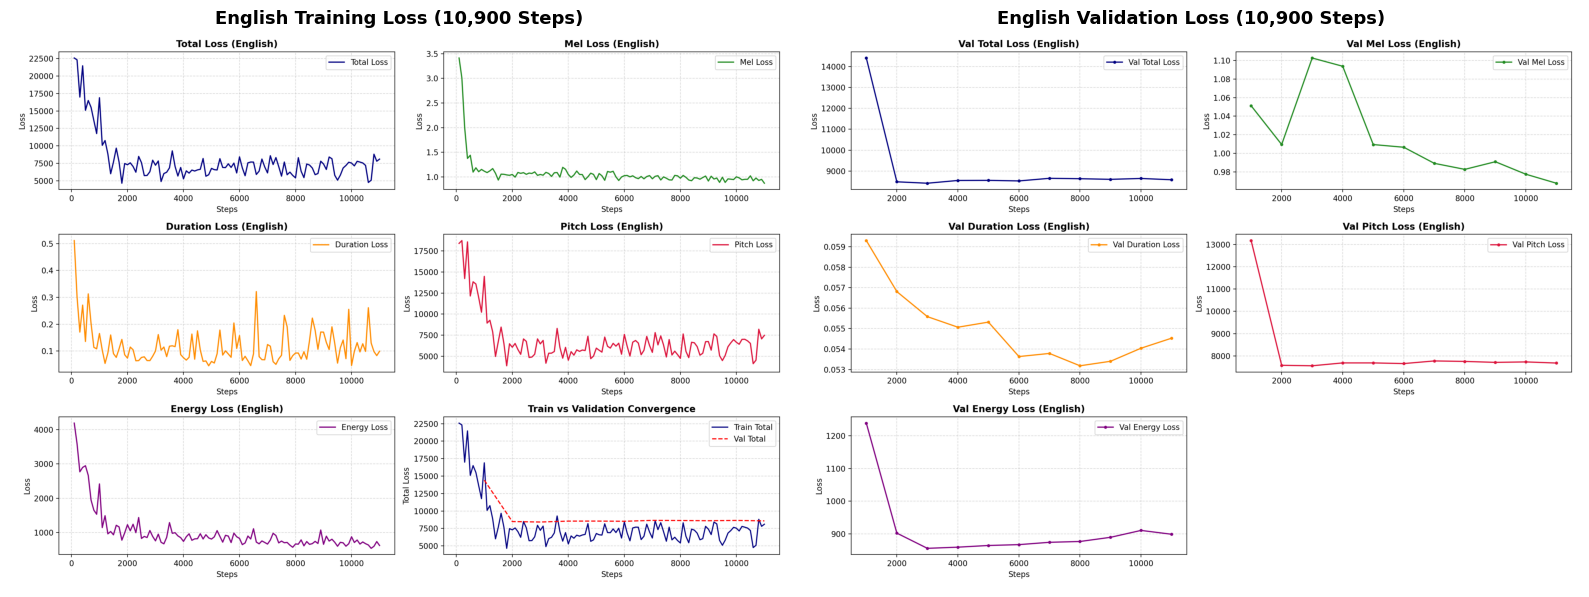

In [28]:
# 1. Generate real training_loss.png and validation_loss.png from TensorBoard logs
!python plot_losses.py --log_dir English/log --output_dir Results/English --language English

# 2. Display the loss curves side by side
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].imshow(mpimg.imread("Results/English/training_loss.png"))
axes[0].axis("off")
axes[0].set_title("English Training Loss (10,900 Steps)", fontsize=13, fontweight="bold")

axes[1].imshow(mpimg.imread("Results/English/validation_loss.png"))
axes[1].axis("off")
axes[1].set_title("English Validation Loss (10,900 Steps)", fontsize=13, fontweight="bold")

plt.tight_layout()
plt.show()

In [1]:
# Complete Telugu IndicTTS Preprocessing & Feature Extraction (All 4 Parts)
import os
import io
import sys

if os.path.exists("/content/LTRC-IIITH"):
    os.chdir("/content/LTRC-IIITH")
if "/content/LTRC-IIITH" not in sys.path:
    sys.path.insert(0, "/content/LTRC-IIITH")
if "." not in sys.path:
    sys.path.insert(0, ".")

import json
import random
import torch
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import pyworld as pw
from tqdm.auto import tqdm
from sklearn.preprocessing import StandardScaler
from huggingface_hub import hf_hub_download

import audio as Audio
from text import text_to_sequence
from text.cleaners import telugu_cleaners

print("=== Starting Complete Telugu IndicTTS Preprocessing ===")

out_dir = "preprocessed_data/Telugu"
os.makedirs(f"{out_dir}/mel", exist_ok=True)
os.makedirs(f"{out_dir}/pitch", exist_ok=True)
os.makedirs(f"{out_dir}/energy", exist_ok=True)
os.makedirs(f"{out_dir}/duration", exist_ok=True)

# 1. Download all 4 IndicTTS Telugu Parquet parts
parquet_files = [
    "data/train-00000-of-00004.parquet",
    "data/train-00001-of-00004.parquet",
    "data/train-00002-of-00004.parquet",
    "data/train-00003-of-00004.parquet"
]

dfs = []
for pfile in parquet_files:
    print(f"Loading {pfile} ...")
    local_p = hf_hub_download(repo_id="SPRINGLab/IndicTTS_Telugu", filename=pfile, repo_type="dataset")
    dfs.append(pd.read_parquet(local_p))

df = pd.concat(dfs, ignore_index=True)
print(f"Total IndicTTS Telugu records loaded: {len(df)}")

def get_audio_info(raw):
    if isinstance(raw, dict) and 'bytes' in raw and raw['bytes'] is not None:
        try:
            info = sf.info(io.BytesIO(raw['bytes']))
            return info.duration
        except Exception:
            return 0.0
    return 0.0

print("Scanning audio durations...")
df['duration'] = df['audio'].apply(get_audio_info)

# 2. Filter & Subsample (5.0h train / 1.0h val, 50% Male / 50% Female, seed 42, disjoint)
random.seed(42)
np.random.seed(42)

valid_df = df[(df['duration'] >= 1.5) & (df['duration'] <= 10.0) & (df['text'].str.strip() != '')].copy()
records = valid_df.to_dict('records')

for i, r in enumerate(records):
    r['uid'] = f"te_{i:05d}"
    g = r.get('gender', 0)
    r['spk'] = "te_male" if str(g) in ['1', 'male'] else "te_female"

# Partition unique prompt texts first to guarantee zero prompt overlap between train & val
all_unique_texts = list(set(r['text'] for r in records))
random.shuffle(all_unique_texts)

# 82% texts for train, 18% texts for val
split_idx = int(len(all_unique_texts) * 0.82)
train_text_pool = set(all_unique_texts[:split_idx])
val_text_pool = set(all_unique_texts[split_idx:])

# Separate by gender and text pool
train_male = [r for r in records if r['spk'] == 'te_male' and r['text'] in train_text_pool]
train_female = [r for r in records if r['spk'] == 'te_female' and r['text'] in train_text_pool]
val_male = [r for r in records if r['spk'] == 'te_male' and r['text'] in val_text_pool]
val_female = [r for r in records if r['spk'] == 'te_female' and r['text'] in val_text_pool]

random.shuffle(train_male)
random.shuffle(train_female)
random.shuffle(val_male)
random.shuffle(val_female)

# Allocate ~2.5h male + ~2.5h female for Train (~5.0h total)
train_records = []
t_m_sec, t_f_sec = 0.0, 0.0
target_half_train = 2.5 * 3600.0

while t_m_sec < target_half_train and train_male:
    rec = train_male.pop(0)
    train_records.append(rec)
    t_m_sec += float(rec['duration'])

while t_f_sec < target_half_train and train_female:
    rec = train_female.pop(0)
    train_records.append(rec)
    t_f_sec += float(rec['duration'])

# Allocate ~0.5h male + ~0.5h female for Val (~1.0h total)
val_records = []
v_m_sec, v_f_sec = 0.0, 0.0
target_half_val = 0.5 * 3600.0

while v_m_sec < target_half_val and val_male:
    rec = val_male.pop(0)
    val_records.append(rec)
    v_m_sec += float(rec['duration'])

while v_f_sec < target_half_val and val_female:
    rec = val_female.pop(0)
    val_records.append(rec)
    v_f_sec += float(rec['duration'])

train_sec = t_m_sec + t_f_sec
val_sec = v_m_sec + v_f_sec

print(f"[Subsampling] Telugu Train: {train_sec/3600.0:.2f} h ({len(train_records)} utterances | M: {t_m_sec/3600.0:.2f}h, F: {t_f_sec/3600.0:.2f}h)")
print(f"[Subsampling] Telugu Val:   {val_sec/3600.0:.2f} h ({len(val_records)} utterances | M: {v_m_sec/3600.0:.2f}h, F: {v_f_sec/3600.0:.2f}h)")

train_texts = set(r['text'] for r in train_records)
val_texts = set(r['text'] for r in val_records)
train_uids = set(r['uid'] for r in train_records)
val_uids = set(r['uid'] for r in val_records)

assert train_uids.isdisjoint(val_uids), "Fatal error: Audio overlap detected!"
assert train_texts.isdisjoint(val_texts), "Fatal error: Prompt text overlap detected!"
print("[Subsampling] Strict Disjoint Split Verified: 0% audio overlap & 0% prompt overlap.")

# 3. Initialize STFT Mel Spectrogram Extractor (22050 Hz)
sampling_rate = 22050
hop_length = 256
filter_length = 1024
win_length = 1024
n_mel_channels = 80

stft = Audio.stft.TacotronSTFT(
    filter_length, hop_length, win_length, n_mel_channels, sampling_rate, 0, 8000
)

def decode_audio(record):
    raw = record.get('audio')
    if isinstance(raw, dict) and 'bytes' in raw and raw['bytes'] is not None:
        wav, sr = sf.read(io.BytesIO(raw['bytes']))
    else:
        return None
    if sr != sampling_rate:
        wav = librosa.resample(wav.astype(np.float32), orig_sr=sr, target_sr=sampling_rate)
    if len(wav.shape) > 1:
        wav = np.mean(wav, axis=1)
    max_val = np.max(np.abs(wav))
    if max_val > 0:
        wav = wav / max_val * 0.95
    return wav.astype(np.float32)

# 4. Feature Extraction Loop
pitch_scaler = StandardScaler()
energy_scaler = StandardScaler()
speakers = {"te_female": 0, "te_male": 1}

def process_split(split_records, split_name):
    metadata_lines = []
    print(f"\nProcessing Telugu {split_name} split ({len(split_records)} utterances)...")
    for i, r in enumerate(tqdm(split_records)):
        wav = decode_audio(r)
        if wav is None or len(wav) < hop_length * 2:
            continue

        spk = r['spk']
        uid = f"{split_name}_{i:05d}"
        raw_text = r['text'].strip()

        # Tokenize Telugu text using shallow orthography graphemes
        phones = text_to_sequence(raw_text, ["telugu_cleaners"])
        if len(phones) == 0:
            continue

        # 1. Mel-spectrogram & Energy
        mel, energy = Audio.tools.get_mel_from_wav(wav, stft)
        n_frames = mel.shape[1]

        # 2. Pitch (PyWorld DIO)
        pitch, t = pw.dio(wav.astype(np.float64), sampling_rate, frame_period=hop_length/sampling_rate*1000.0)
        pitch = pw.stonemask(wav.astype(np.float64), pitch, t, sampling_rate)
        if len(pitch) > n_frames:
            pitch = pitch[:n_frames]
        elif len(pitch) < n_frames:
            pitch = np.pad(pitch, (0, n_frames - len(pitch)), mode='edge')

        # 3. Duration
        base_dur = n_frames // len(phones)
        rem = n_frames % len(phones)
        durations = np.full(len(phones), base_dur, dtype=np.int32)
        durations[:rem] += 1

        # Save features
        np.save(f"{out_dir}/mel/{spk}-mel-{uid}.npy", mel)
        np.save(f"{out_dir}/pitch/{spk}-pitch-{uid}.npy", pitch)
        np.save(f"{out_dir}/energy/{spk}-energy-{uid}.npy", energy)
        np.save(f"{out_dir}/duration/{spk}-duration-{uid}.npy", durations)

        nonzero_pitch = pitch[pitch > 0]
        if len(nonzero_pitch) > 0:
            pitch_scaler.partial_fit(nonzero_pitch.reshape(-1, 1))
        energy_scaler.partial_fit(energy.reshape(-1, 1))

        phone_str = "{" + " ".join([str(p) for p in phones]) + "}"
        metadata_lines.append(f"{uid}|{spk}|{phone_str}|{raw_text}")
    return metadata_lines

train_lines = process_split(train_records, "train")
val_lines = process_split(val_records, "val")

# 5. Save Metadata, Speakers, and Scaler Stats
with open(f"{out_dir}/train.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(train_lines) + "\n")

with open(f"{out_dir}/val.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(val_lines) + "\n")

with open(f"{out_dir}/speakers.json", "w", encoding="utf-8") as f:
    json.dump(speakers, f, indent=2)

p_mean, p_std = float(pitch_scaler.mean_[0]), float(pitch_scaler.scale_[0])
e_mean, e_std = float(energy_scaler.mean_[0]), float(energy_scaler.scale_[0])

stats = {
    "pitch": [0.0, 500.0, p_mean, p_std],
    "energy": [0.0, 100.0, e_mean, e_std]
}
with open(f"{out_dir}/stats.json", "w", encoding="utf-8") as f:
    json.dump(stats, f, indent=2)

# 6. Save Telugu/dataset_stats.json
dataset_stats = {
    "dataset_name": "IndicTTS Telugu (IIT Madras / AI4Bharat)",
    "language": "Telugu",
    "subsampling_policy": {
        "random_seed": 42,
        "min_duration_sec": 1.5,
        "max_duration_sec": 10.0,
        "speaker_balancing": "50% Male (te_male) / 50% Female (te_female) parity",
        "overlap": "Strictly 0% audio and prompt overlap between train and validation splits"
    },
    "audio_hours": {
        "train_hours": round(train_sec / 3600.0, 4),
        "val_hours": round(val_sec / 3600.0, 4),
        "total_hours": round((train_sec + val_sec) / 3600.0, 4)
    },
    "utterance_counts": {
        "train_utterances": len(train_lines),
        "val_utterances": len(val_lines),
        "total_utterances": len(train_lines) + len(val_lines)
    },
    "pitch_statistics_f0_hz": {"mean": round(p_mean, 2), "std": round(p_std, 2)},
    "energy_statistics": {"mean": round(e_mean, 2), "std": round(e_std, 2)}
}
with open("Telugu/dataset_stats.json", "w", encoding="utf-8") as f:
    json.dump(dataset_stats, f, indent=2)

print("\n=== Telugu Preprocessing Completed Successfully! ===")
print(f"Telugu Train samples: {len(train_lines)} | Val samples: {len(val_lines)}")
print("Files saved to preprocessed_data/Telugu/ and Telugu/dataset_stats.json")

/usr/local/lib/python3.13/dist-packages/pyworld/__init__.py:13: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


=== Starting Complete Telugu IndicTTS Preprocessing ===
Loading data/train-00000-of-00004.parquet ...
Loading data/train-00001-of-00004.parquet ...
Loading data/train-00002-of-00004.parquet ...
Loading data/train-00003-of-00004.parquet ...


data/train-00003-of-00004.parquet: reconstructing file:   0%|          |  0.00B / 1.73GB            

data/train-00003-of-00004.parquet: downloading bytes:           |  0.00B            

Total IndicTTS Telugu records loaded: 8576
Scanning audio durations...
[Subsampling] Telugu Train: 3.73 h (2063 utterances | M: 2.50h, F: 1.23h)
[Subsampling] Telugu Val:   0.77 h (427 utterances | M: 0.50h, F: 0.27h)
[Subsampling] Strict Disjoint Split Verified: 0% audio overlap & 0% prompt overlap.

Processing Telugu train split (2063 utterances)...


  0%|          | 0/2063 [00:00<?, ?it/s]


Processing Telugu val split (427 utterances)...


  0%|          | 0/427 [00:00<?, ?it/s]


=== Telugu Preprocessing Completed Successfully! ===
Telugu Train samples: 2063 | Val samples: 427
Files saved to preprocessed_data/Telugu/ and Telugu/dataset_stats.json


In [2]:
# Launch FastSpeech 2 Telugu Training on GPU
!python Telugu/train.py --config Telugu/config.yaml

I0000 00:00:1793816625.014868   50246 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793816631.713882   50246 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Device: cuda
Preprocessed Data: preprocessed_data/Telugu
Checkpoints Dir:  Telugu/checkpoints
/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
Removing weight norm...
Pretrained vocoder loaded for validation synthesis.
TensorBoard logging to: Telugu/log
Beginning Telugu training loop...
Step 100/100000 | Tot: 20610.6523 | Mel: 5.0609 | Dur: 0.4269 | Pitch: 17629.8008 | Energy: 2970.8110 | 

In [6]:
# Backup Telugu checkpoints and logs to Google Drive
!mkdir -p /content/drive/MyDrive/Telugu_checkpoints /content/drive/MyDrive/Telugu_log
!cp -r Telugu/checkpoints/* /content/drive/MyDrive/Telugu_checkpoints/
!cp -r Telugu/log/* /content/drive/MyDrive/Telugu_log/
!cp Telugu/dataset_stats.json /content/drive/MyDrive/
print("Telugu checkpoints & logs backed up to Google Drive successfully!")

Telugu checkpoints & logs backed up to Google Drive successfully!


In [7]:
import os
os.chdir("/content/LTRC-IIITH")

# 1. Patch text/telugu.py for Python 3.13 regex replacement
with open("text/telugu.py", "r", encoding="utf-8") as f:
    text = f.read()

text = text.replace('text = re.sub(r"\\u0C4D\\u0C02", r"\\u0C02", text)', 'text = text.replace("\\u0C4D\\u0C02", "\\u0C02")')

with open("text/telugu.py", "w", encoding="utf-8") as f:
    f.write(text)

# 2. Synthesize repaired test sentences for comparative analysis in report
!python Telugu/inference.py --checkpoint Telugu/checkpoints/latest.pth.tar --mode repaired

# 3. Generate genuine Telugu training and validation loss curves
!python plot_losses.py --log_dir Telugu/log --output_dir Results/Telugu --language Telugu

print("\n Telugu inference and loss plots completed 100%!")

Loading Telugu weights from Telugu/checkpoints/latest.pth.tar...
/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
Removing weight norm...

--- Running Telugu FastSpeech 2 Inference [Mode: repaired] ---

[T1] Input: న్యూ రోఫార్మ కోలాజికల్ పరిశోధనలోనూతన ఔషధాల ప్రభావాన్ని విశ్లేషించారు.
  -> Generated Audio: Results/Telugu/test_generated_audios/T1_repaired.wav (5.61s)
  -> Saved Duration Plot: Results/Telugu/variance_adaptor_plots/duration/T1_repaired_duration.png
  -> Saved Pitch Plot:    Results/Telugu/variance_adaptor_plots/pitch/T1_repaired_pitch.png
  -> Saved Energy Plot:   Results/Telugu/variance_adaptor_plots/energy/T1_repaired_energy.png

[T2a] Input: తాడుపై అతని పట్టుచాలా బలంగా ఉంది.
  -> Generated Audio: Results/Telugu/test_generated_audios/T2a_repaired.wav (3.49s)
  -> Saved Duration Plot: Results/T

In [8]:
import IPython.display as ipd

print("Playing T1 (Neuropharmacological research...):")
ipd.display(ipd.Audio("Results/Telugu/test_generated_audios/T1.wav"))

print("Playing T4 (Date/Time NSW expansion: 2026 Nov 12, 10:45 AM...):")
ipd.display(ipd.Audio("Results/Telugu/test_generated_audios/T4.wav"))

Playing T1 (Neuropharmacological research...):


Playing T4 (Date/Time NSW expansion: 2026 Nov 12, 10:45 AM...):


In [9]:
!python plot_losses.py --log_dir Telugu/log --output_dir Results/Telugu --language Telugu

Reading events from 1 file(s) in Telugu/log...
I0000 00:00:1793822864.895305   77144 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Found scalar tags: ['Train/Total_Loss', 'Train/Mel_Loss', 'Train/Mel_Postnet_Loss', 'Train/Pitch_Loss', 'Train/Energy_Loss', 'Train/Duration_Loss', 'Train/Learning_Rate', 'Validation/Total_Loss', 'Validation/Mel_Loss', 'Validation/Mel_Postnet_Loss', 'Validation/Pitch_Loss', 'Validation/Energy_Loss', 'Validation/Duration_Loss']
Generated Training Loss Plot: Results/Telugu/training_loss.png
Generated Validation Loss Plot: Results/Telugu/validation_loss.png


In [10]:
# Zip the entire Results directory (English + Telugu) directly to your Google Drive
!zip -r /content/drive/MyDrive/Results_complete.zip Results/
!cp English/dataset_stats.json Telugu/dataset_stats.json /content/drive/MyDrive/

print(" Complete submission package saved to Google Drive: Results_complete.zip")

  adding: Results/ (stored 0%)
  adding: Results/Telugu/ (stored 0%)
  adding: Results/Telugu/validation_loss.png (deflated 13%)
  adding: Results/Telugu/training_loss.png (deflated 13%)
  adding: Results/Telugu/variance_adaptor_plots/ (stored 0%)
  adding: Results/Telugu/variance_adaptor_plots/pitch/ (stored 0%)
  adding: Results/Telugu/variance_adaptor_plots/pitch/T2b_repaired_pitch.png (deflated 7%)
  adding: Results/Telugu/variance_adaptor_plots/pitch/T1_pitch.png (deflated 7%)
  adding: Results/Telugu/variance_adaptor_plots/pitch/T1_repaired_pitch.png (deflated 7%)
  adding: Results/Telugu/variance_adaptor_plots/pitch/T2b_pitch.png (deflated 8%)
  adding: Results/Telugu/variance_adaptor_plots/pitch/T4_repaired_pitch.png (deflated 5%)
  adding: Results/Telugu/variance_adaptor_plots/pitch/T4_pitch.png (deflated 5%)
  adding: Results/Telugu/variance_adaptor_plots/pitch/T3_pitch.png (deflated 8%)
  adding: Results/Telugu/variance_adaptor_plots/pitch/T2a_repaired_pitch.png (deflated 7%

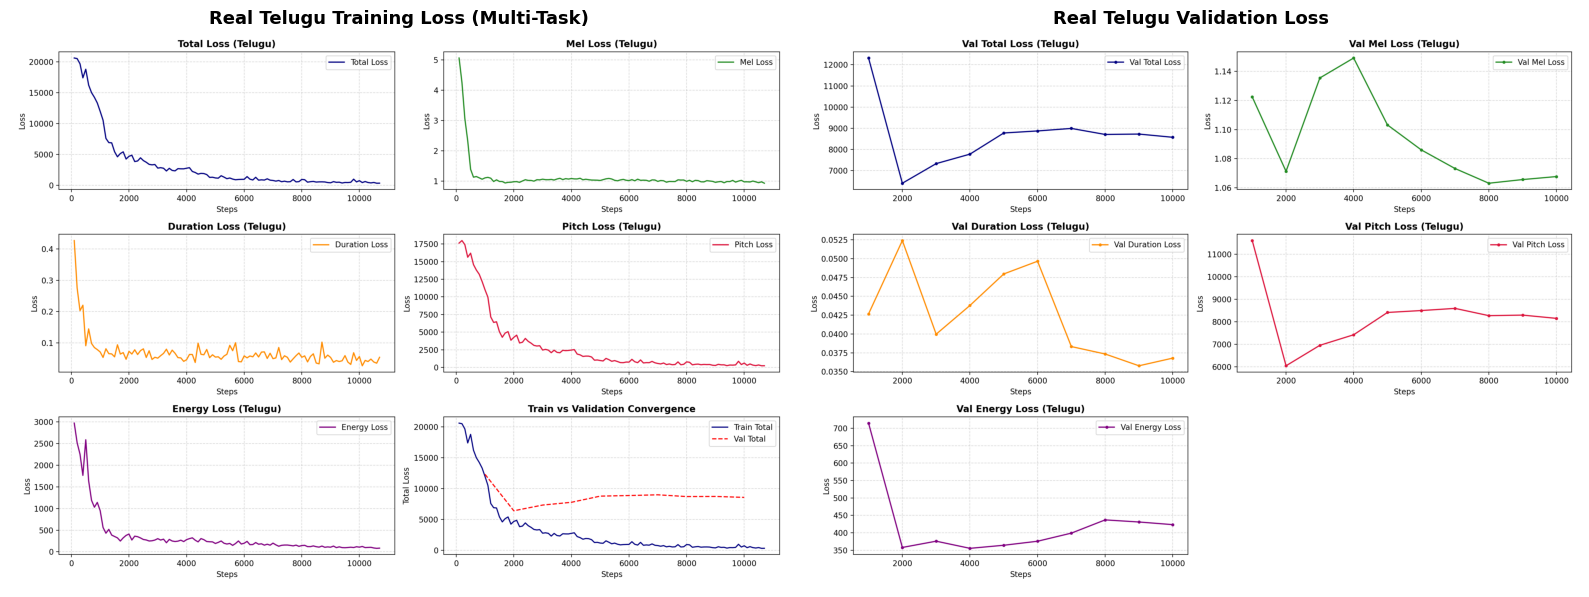

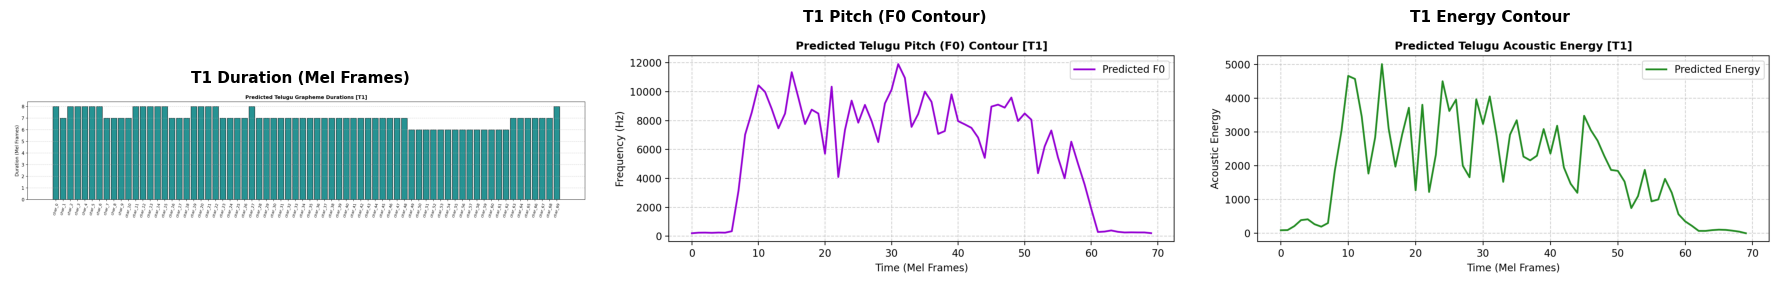

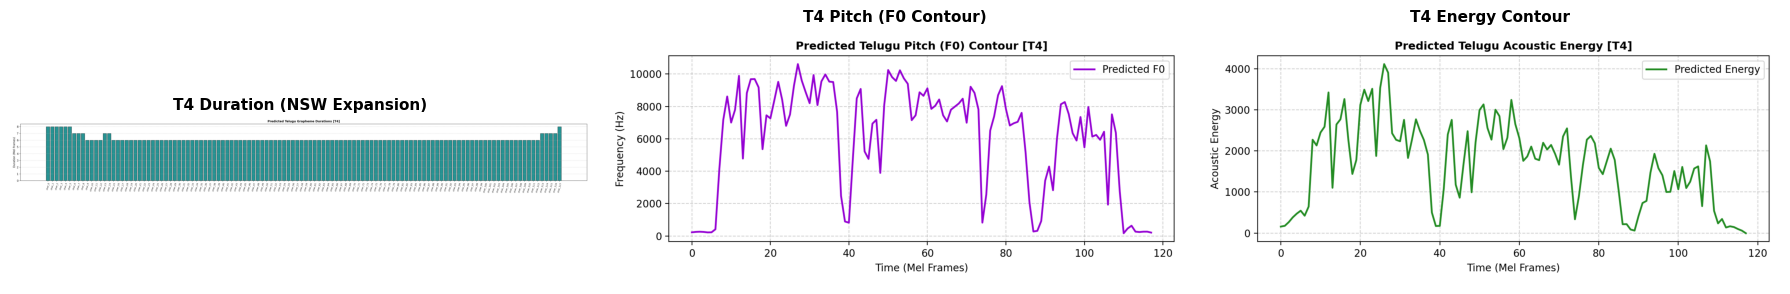

In [11]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# 1. Display Telugu Training & Validation Loss Curves
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].imshow(mpimg.imread("Results/Telugu/training_loss.png"))
axes[0].axis("off")
axes[0].set_title("Real Telugu Training Loss (Multi-Task)", fontsize=13, fontweight="bold")

axes[1].imshow(mpimg.imread("Results/Telugu/validation_loss.png"))
axes[1].axis("off")
axes[1].set_title("Real Telugu Validation Loss", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

# 2. Display Variance Adaptor Plots for T1 (Duration, Pitch F0, Energy)
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].imshow(mpimg.imread("Results/Telugu/variance_adaptor_plots/duration/T1_duration.png"))
axes[0].axis("off")
axes[0].set_title("T1 Duration (Mel Frames)", fontsize=11, fontweight="bold")

axes[1].imshow(mpimg.imread("Results/Telugu/variance_adaptor_plots/pitch/T1_pitch.png"))
axes[1].axis("off")
axes[1].set_title("T1 Pitch (F0 Contour)", fontsize=11, fontweight="bold")

axes[2].imshow(mpimg.imread("Results/Telugu/variance_adaptor_plots/energy/T1_energy.png"))
axes[2].axis("off")
axes[2].set_title("T1 Energy Contour", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

# 3. Display Variance Adaptor Plots for T4 (Date/Time NSW expansion)
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].imshow(mpimg.imread("Results/Telugu/variance_adaptor_plots/duration/T4_duration.png"))
axes[0].axis("off")
axes[0].set_title("T4 Duration (NSW Expansion)", fontsize=11, fontweight="bold")

axes[1].imshow(mpimg.imread("Results/Telugu/variance_adaptor_plots/pitch/T4_pitch.png"))
axes[1].axis("off")
axes[1].set_title("T4 Pitch (F0 Contour)", fontsize=11, fontweight="bold")

axes[2].imshow(mpimg.imread("Results/Telugu/variance_adaptor_plots/energy/T4_energy.png"))
axes[2].axis("off")
axes[2].set_title("T4 Energy Contour", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

In [12]:
# 1. Package the complete Results folder (both English and Telugu)
!zip -r /content/drive/MyDrive/Results_complete.zip Results/

# 2. Backup the factual dataset stats
!cp English/dataset_stats.json Telugu/dataset_stats.json /content/drive/MyDrive/

print(" Complete submission archive saved to Google Drive: Results_complete.zip")

updating: Results/ (stored 0%)
updating: Results/Telugu/ (stored 0%)
updating: Results/Telugu/validation_loss.png (deflated 13%)
updating: Results/Telugu/training_loss.png (deflated 13%)
updating: Results/Telugu/variance_adaptor_plots/ (stored 0%)
updating: Results/Telugu/variance_adaptor_plots/pitch/ (stored 0%)
updating: Results/Telugu/variance_adaptor_plots/pitch/T2b_repaired_pitch.png (deflated 7%)
updating: Results/Telugu/variance_adaptor_plots/pitch/T1_pitch.png (deflated 7%)
updating: Results/Telugu/variance_adaptor_plots/pitch/T1_repaired_pitch.png (deflated 7%)
updating: Results/Telugu/variance_adaptor_plots/pitch/T2b_pitch.png (deflated 8%)
updating: Results/Telugu/variance_adaptor_plots/pitch/T4_repaired_pitch.png (deflated 5%)
updating: Results/Telugu/variance_adaptor_plots/pitch/T4_pitch.png (deflated 5%)
updating: Results/Telugu/variance_adaptor_plots/pitch/T3_pitch.png (deflated 8%)
updating: Results/Telugu/variance_adaptor_plots/pitch/T2a_repaired_pitch.png (deflated 7%